# Regional Momentum on the MSCI ACWI

**2270 Financial Modeling, Group Assignment**

- Moodle group: *TODO*
- Members: *TODO*
- Streamlit app: *TODO (URL)*
- GitHub repository: *TODO (URL)*

## Setup
Open this notebook in Google Colab and choose *Runtime > Run all*. No data files are needed: all data are
downloaded through APIs (Yahoo Finance via `yfinance`, FRED, SEC EDGAR). A full run takes a few minutes,
mostly for downloading the SEC holdings reports. Missing packages are installed in the first code cell.

## The strategy in short
The portfolio rebuilds the MSCI ACWI from six regional ETFs (SPY, IEV, EEM, EWJ, EWC, EPP). On the last
trading day of June and December it starts from the current ACWI region weights, ranks the regions by
their total return over the past 12 months and tilts the weights by +6/+4/+2/-2/-4/-6 percentage points.
No region may deviate by more than 50% from its ACWI weight; if a limit binds, the other side is scaled
down so that the weights still add up to 100%. Trading costs are 15 bp of the traded volume.

## Notebook structure
1. Strategy code (also used by the Streamlit app)
2. Parameters and data
3. Backtest and performance measures
4. Figures and tables for the prospectus
5. Sensitivity analysis
6. Check against the app

## Generative AI disclosure
*TODO: tools, purpose, how outputs were checked.*


In [1]:
# install packages that are missing (Colab already has most of them)
import importlib.util
import subprocess
import sys

for package in ["yfinance", "statsmodels"]:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

# 1. Strategy code
The same code is used by the Streamlit app (`regional_momentum/core.py` in the repository).

### Code: Imports and settings
The six regional ETFs that make up the portfolio, the benchmark, and the default assumptions of the strategy. Changing a value in Params changes the backtest.

In [2]:
import hashlib
import html
import re
import time
from dataclasses import dataclass, replace
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import statsmodels.api as sm
import yfinance as yf

REGIONS = ["USA", "Europe", "Emerging Markets", "Japan", "Canada", "Pacific ex Japan"]
ETF = {
    "USA": "SPY",
    "Europe": "IEV",
    "Emerging Markets": "EEM",
    "Japan": "EWJ",
    "Canada": "EWC",
    "Pacific ex Japan": "EPP",
}
BENCHMARK = "ACWI"

# iShares MSCI ACWI ETF on SEC EDGAR. The SEC wants automated downloads to include a contact e-mail.
SEC_SERIES = "S000021461"
SEC_HEADERS = {"User-Agent": "FM-Group-Project research@example.com"}
SEC_FORMS = ["N-Q", "NPORT-EX", "NPORT-P"]


@dataclass
class Params:
    start: str = "2008-06-30"
    end: str = "2026-10-31"
    rebalance: str = "S"            # "Q" quarterly, "S" semi-annual (Jun/Dec), "A" annual (Dec)
    lookback_months: int = 12       # momentum = total return over this many months
    tilt_pp: float = 6.0            # active weight of the best region, in percentage points
    max_rel_deviation: float = 0.5  # 0.5 = each weight stays between 0.5x and 1.5x its ACWI weight
    cost_bps: float = 15.0          # trading costs in basis points of the traded volume

### Code: Market data
ETF prices come from Yahoo Finance (yfinance), the risk-free rate from FRED.

In [3]:
def load_prices(start, end):
    """Daily closing prices of the six ETFs and ACWI, adjusted for dividends and splits."""
    # 13 extra months, so that the first 12-month momentum signal can be calculated
    first_day = pd.Timestamp(start) - pd.DateOffset(months=13)
    last_day = pd.Timestamp(end) + pd.Timedelta(days=1)  # yfinance leaves out the end date itself
    tickers = list(ETF.values()) + [BENCHMARK]

    data = yf.download(tickers, start=first_day, end=last_day, auto_adjust=True, progress=False)
    prices = data["Close"][tickers]
    prices.index = pd.DatetimeIndex(prices.index).tz_localize(None)
    return prices.dropna(subset=list(ETF.values()))


def load_riskfree(start, end):
    """Monthly risk-free return from the 3-month T-bill rate (FRED series DTB3)."""
    url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DTB3"
    data = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".")
    yearly_rate = data.iloc[:, 0].ffill() / 100

    # rate at the end of each month, turned into a one-month return
    month_end_rate = yearly_rate.resample("ME").last()
    monthly_return = (1 + month_end_rate) ** (1 / 12) - 1

    # month m earns the rate that was known at the end of month m-1
    rf = monthly_return.shift(1)
    return rf.loc[start:end].rename("rf")

### Code: ACWI region weights from SEC filings
The iShares MSCI ACWI ETF reports its holdings to the SEC every quarter. We download these reports, add up the weights per country and group the countries into our six regions. Until 2019 the reports are HTML tables by country (forms N-Q and NPORT-EX), since then XML files with every single holding (form NPORT-P).

In [4]:
EUROPE = {
    "UNITED KINGDOM", "SWITZERLAND", "FRANCE", "GERMANY", "NETHERLANDS", "SWEDEN", "DENMARK",
    "ITALY", "SPAIN", "FINLAND", "BELGIUM", "NORWAY", "IRELAND", "AUSTRIA", "PORTUGAL", "LUXEMBOURG",
}
PACIFIC = {"AUSTRALIA", "HONG KONG", "SINGAPORE", "NEW ZEALAND", "MACAU"}
EMERGING = {
    "ARGENTINA", "BRAZIL", "CHILE", "CHINA", "COLOMBIA", "CZECH REPUBLIC", "EGYPT", "HUNGARY",
    "INDIA", "INDONESIA", "KUWAIT", "MALAYSIA", "MEXICO", "PAKISTAN", "PERU", "PHILIPPINES",
    "POLAND", "QATAR", "RUSSIA", "SAUDI ARABIA", "SOUTH AFRICA", "SOUTH KOREA", "KOREA",
    "TAIWAN", "THAILAND", "TURKEY", "UNITED ARAB EMIRATES",
}
ALL_COUNTRIES = {"UNITED STATES", "CANADA", "JAPAN", "ISRAEL", "GREECE"} | EUROPE | PACIFIC | EMERGING

# MSCI moved two countries during our sample period
ISRAEL_DEVELOPED_FROM = pd.Timestamp("2010-06-01")
GREECE_EMERGING_FROM = pd.Timestamp("2013-12-01")

# Two-letter country codes used in the NPORT-P files
EUROPE_CODES = {"GB", "CH", "FR", "DE", "NL", "SE", "DK", "IT", "ES", "FI", "BE", "NO", "IE", "AT", "PT", "LU", "JE", "IM", "IL"}
PACIFIC_CODES = {"AU", "HK", "SG", "NZ", "MO"}
# Countries where many US companies are registered (e.g. Medtronic in Ireland, Chubb in Switzerland)
US_COMPANY_CODES = {"US", "IE", "CH", "NL", "GB", "BM", "LU", "LR", "CW", "PA", "JE", "IM", "IL", "PR", "BS"}
EUROPE_CURRENCIES = {"EUR", "GBP", "GBX", "CHF", "SEK", "DKK", "NOK", "ILS"}


def region_of_country(country, report_date):
    """Region of a country name as printed in the HTML reports."""
    country = country.upper()
    if country == "UNITED STATES":
        return "USA"
    if country == "CANADA":
        return "Canada"
    if country == "JAPAN":
        return "Japan"
    if country == "ISRAEL":
        return "Europe" if report_date >= ISRAEL_DEVELOPED_FROM else "Emerging Markets"
    if country == "GREECE":
        return "Emerging Markets" if report_date >= GREECE_EMERGING_FROM else "Europe"
    if country in EUROPE:
        return "Europe"
    if country in PACIFIC:
        return "Pacific ex Japan"
    return "Emerging Markets"


def region_of_holding(country_code, currency, name, report_date):
    """Region of a single NPORT-P holding.

    NPORT-P gives the country where a company is registered, not the MSCI country. The trading
    currency fixes most cases: Medtronic is registered in Ireland but trades in USD (= USA),
    Alibaba is registered in the Cayman Islands and trades in HKD or USD (= Emerging Markets).
    """
    if "ISHARES" in name:  # the fund sometimes holds a country ETF, e.g. iShares MSCI India ETF
        if "JAPAN" in name:
            return "Japan"
        if "CANADA" in name:
            return "Canada"
        return "Emerging Markets"
    if country_code == "GR":
        return region_of_country("GREECE", report_date)

    if currency == "USD":
        if country_code == "CA":
            return "Canada"
        if country_code == "JP":
            return "Japan"
        if country_code in PACIFIC_CODES:
            return "Pacific ex Japan"
        if country_code in US_COMPANY_CODES:
            return "USA"
        return "Emerging Markets"  # e.g. Chinese, Indian or Brazilian shares traded in USD
    if currency == "CAD":
        return "Canada"
    if currency == "JPY":
        return "Japan"
    if currency in EUROPE_CURRENCIES:
        return "Europe"
    if currency in ("AUD", "NZD", "SGD"):
        return "Pacific ex Japan"
    if currency == "HKD":
        return "Pacific ex Japan" if country_code in ("HK", "MO") else "Emerging Markets"
    return "Emerging Markets"


def find(pattern, text):
    """First group of a regular expression, or an empty string if there is no match."""
    match = re.search(pattern, text, re.S)
    return match.group(1) if match else ""


def to_weights(totals):
    """Turn summed percentages per region into weights that add up to 1."""
    weights = pd.Series(totals, dtype=float).reindex(REGIONS).fillna(0.0)
    total = weights.sum()
    if total < 95 or total > 101:  # the rest is cash; anything else means the parsing went wrong
        raise ValueError(f"Country weights add up to {total:.1f}% instead of about 100%")
    return weights / total


def weights_from_html(document, report_date):
    """Region weights from an HTML report (N-Q or NPORT-EX)."""
    # remove the HTML tags and collapse the white space
    text = html.unescape(re.sub(r"<[^>]+>", " ", document))
    text = re.sub(r"\s+", " ", text)

    # One report covers many iShares funds. The ACWI table starts with the fund name, followed by the
    # column headers and "Common Stocks". The currency-hedged ACWI fund is a different fund.
    start = None
    for match in re.finditer(r"MSCI ACWI (INDEX FUND|Index Fund|ETF)\b", text):
        before = text[max(0, match.start() - 40): match.start()]
        after = text[match.start(): match.start() + 160]
        if "Hedged" not in before and re.search(r"Security Shares Value (COMMON STOCKS|Common Stocks)", after):
            start = match.start()
            break
    if start is None:
        raise ValueError("ACWI table not found in the report")
    end = start + re.search(r"TOTAL INVESTMENTS|Total Investments", text[start:]).start()
    table = text[start:end]

    # country lines look like "JAPAN — 9.29%" (older reports) or "Japan — 7.5%" (newer reports)
    country_names = "|".join(sorted(ALL_COUNTRIES, key=len, reverse=True))
    pattern = r"(?<![A-Za-z])(" + country_names + r") ?[—–] ?(\d+(?:\.\d+)?)%"

    totals = {}
    for country, percent in re.findall(pattern, table, re.I):
        region = region_of_country(country, report_date)
        totals[region] = totals.get(region, 0.0) + float(percent)
    return to_weights(totals)


def weights_from_nport(xml, report_date):
    """Region weights from an NPORT-P XML file, one <invstOrSec> block per holding."""
    totals = {}
    for holding in re.findall(r"<invstOrSec>(.*?)</invstOrSec>", xml, re.S):
        asset_type = find(r"<assetCat>(.*?)</assetCat>", holding)
        if asset_type not in ("EC", "EP"):  # only common and preferred shares, no cash or futures
            continue
        percent = float(find(r"<pctVal>(.*?)</pctVal>", holding))  # already in percent
        country_code = find(r'invCountry="?([A-Z]{2})', holding) or find(r"<invCountry>(.*?)</invCountry>", holding)
        currency = find(r'curCd="([A-Z]{3})"', holding) or find(r"<curCd>(.*?)</curCd>", holding)
        name = find(r"<name>(.*?)</name>", holding).upper()

        region = region_of_holding(country_code, currency, name, report_date)
        totals[region] = totals.get(region, 0.0) + percent
    return to_weights(totals)


def sec_download(url, cache_folder=None):
    """Download a page from SEC EDGAR; with a cache folder each file is only downloaded once."""
    cache_file = None
    if cache_folder is not None:
        Path(cache_folder).mkdir(parents=True, exist_ok=True)
        cache_file = Path(cache_folder) / hashlib.sha1(url.encode()).hexdigest()
        if cache_file.exists():
            return cache_file.read_text(encoding="utf-8")

    time.sleep(0.15)  # the SEC allows at most 10 requests per second
    response = requests.get(url, headers=SEC_HEADERS, timeout=120)
    response.raise_for_status()
    text = response.content.decode("utf-8", "ignore")

    if cache_file is not None:
        cache_file.write_text(text, encoding="utf-8")
    return text


def list_sec_filings():
    """All quarterly holdings filings of the ACWI ETF: form, filing date and link."""
    rows = []
    for form in SEC_FORMS:
        url = (
            "https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany"
            f"&CIK={SEC_SERIES}&type={form}&dateb=&owner=include&count=100&output=atom"
        )
        feed = sec_download(url)  # never cached, so that new filings show up
        for entry in re.findall(r"<entry>(.*?)</entry>", feed, re.S):
            if find(r"<filing-type>(.*?)</filing-type>", entry) != form:  # skips amendments like N-Q/A
                continue
            rows.append({
                "form": form,
                "filed": pd.Timestamp(find(r"<filing-date>(.*?)</filing-date>", entry)),
                "index_url": find(r"<filing-href>(.*?)</filing-href>", entry),
            })
    filings = pd.DataFrame(rows).drop_duplicates("index_url")
    return filings.sort_values("filed").reset_index(drop=True)


def load_acwi_region_weights(cache_folder=None, verbose=True):
    """ACWI region weights for every reporting date, plus the date each report became public."""
    filings = list_sec_filings()
    if verbose:
        print(f"Downloading and parsing {len(filings)} SEC filings ...")

    rows = []
    for filing in filings.itertuples():
        index_page = sec_download(filing.index_url, cache_folder)
        report_date = pd.Timestamp(find(r'Period of Report</div>\s*<div class="info">([\d-]+)<', index_page))
        folder = filing.index_url.rsplit("/", 1)[0]

        if filing.form == "NPORT-P":
            xml = sec_download(folder + "/primary_doc.xml", cache_folder)
            weights = weights_from_nport(xml, report_date)
        else:
            # the main document is the first .htm link that is not an index page or a certification
            links = re.findall(r'href="(/Archives/[^"]+\.htm)"', index_page)
            links = [link for link in links if "-index" not in link and not re.search(r"cert|ex99|ex-99|ethic", link, re.I)]
            document = sec_download("https://www.sec.gov" + links[0], cache_folder)
            weights = weights_from_html(document, report_date)

        rows.append({"period": report_date, "filed": filing.filed, "form": filing.form,
                     "url": filing.index_url, **weights.to_dict()})

    table = pd.DataFrame(rows).sort_values(["period", "filed"])
    table = table.drop_duplicates("period", keep="first")  # one row per reporting date
    return table.set_index("period")

### Code: Allocation rule
On every rebalancing date: (1) take the current ACWI weights, (2) rank the regions by momentum, (3) tilt the weights towards the winners within the limits.

In [5]:
def region_prices(prices):
    """ETF prices with region names as column names."""
    result = prices[[ETF[region] for region in REGIONS]].copy()
    result.columns = REGIONS
    return result


def rebalancing_dates(trading_days, params):
    """First day of the sample, then the last trading day of each rebalancing month."""
    months = {"Q": [3, 6, 9, 12], "S": [6, 12], "A": [12]}[params.rebalance]
    days = trading_days[(trading_days >= pd.Timestamp(params.start)) & (trading_days <= pd.Timestamp(params.end))]

    dates = [days[0]]
    for i, day in enumerate(days):
        last_day_of_month = i == len(days) - 1 or days[i + 1].month != day.month
        if last_day_of_month and day.month in months and day > days[0]:
            dates.append(day)
    return dates


def acwi_weights_on(day, acwi_weights, prices):
    """ACWI weights on a given day, using only reports that were already public.

    The latest public report is usually about two months old, so its weights are rolled forward
    with the price changes of each region since the reporting date.
    """
    public = acwi_weights[acwi_weights["filed"] < day]
    if public.empty:
        raise ValueError(f"No ACWI report was public before {day.date()}")
    report_date = public.index.max()

    weights = public.loc[report_date, REGIONS].astype(float)
    price_change = prices.asof(day) / prices.asof(report_date)
    weights = weights * price_change
    return weights / weights.sum(), report_date


def momentum_on(day, prices, months):
    """Total return of each region over the past `months` months."""
    past_day = day - pd.DateOffset(months=months)
    return prices.asof(day) / prices.asof(past_day) - 1


def target_weights(acwi, momentum, tilt_pp, max_deviation):
    """ACWI weights plus active weights by momentum rank.

    With 6 regions and tilt_pp = 6 the active weights are +6, +4, +2, -2, -4, -6 percentage points.
    No region may move more than max_deviation times its ACWI weight. If that limit cuts some active
    weights, the other side is scaled down so that over- and underweights still cancel out.
    """
    ranking = momentum.sort_values(ascending=False).index  # best region first
    half = len(ranking) // 2
    steps = list(range(half, 0, -1)) + list(range(-1, -half - 1, -1))  # 3, 2, 1, -1, -2, -3

    active = pd.Series(0.0, index=acwi.index)
    for region, step in zip(ranking, steps):
        active[region] = step / half * tilt_pp / 100

    # limit relative to the ACWI weight
    limit = max_deviation * acwi
    active = active.clip(lower=-limit, upper=limit)

    # over- and underweights must add up to zero
    over = active[active > 0].sum()
    under = -active[active < 0].sum()
    if over > under:
        active[active > 0] *= under / over
    elif under > over:
        active[active < 0] *= over / under

    return acwi + active

### Code: Backtest
Day by day: prices move and the weights drift; on rebalancing dates the portfolio is set back to the target weights and trading costs are paid. Signals and trades both use the closing price of the rebalancing day, so every decision only uses information available at that time.

In [6]:
@dataclass
class BacktestResult:
    nav: pd.Series         # portfolio value, starts at 1
    weights: pd.DataFrame  # weights at the end of each day
    trades: pd.DataFrame   # one row per rebalancing date


def run_backtest(prices, acwi_weights, params, with_tilt=True):
    all_prices = region_prices(prices)
    sample = all_prices.loc[params.start:params.end]
    daily_returns = sample.pct_change().fillna(0.0).to_numpy()
    rebalancing_days = set(rebalancing_dates(sample.index, params))

    value = 1.0
    weights = None  # numpy array in the order of REGIONS
    values, weight_history, trades = [], [], []

    for i, day in enumerate(sample.index):
        # 1) prices move: the portfolio value changes and the weights drift
        if weights is not None:
            grown = weights * (1 + daily_returns[i])
            value = value * grown.sum()
            weights = grown / grown.sum()

        # 2) rebalancing: new target weights, trading costs on the traded volume
        if day in rebalancing_days:
            acwi, report_date = acwi_weights_on(day, acwi_weights, all_prices)
            momentum = momentum_on(day, all_prices, params.lookback_months)
            tilt = params.tilt_pp if with_tilt else 0.0
            target = target_weights(acwi, momentum, tilt, params.max_rel_deviation)

            if weights is None:
                turnover = 0.0  # the initial purchase is not charged
            else:
                turnover = float(np.abs(target.to_numpy() - weights).sum())
            cost = turnover * params.cost_bps / 10000
            value = value * (1 - cost)

            trade = {"date": day, "anchor": report_date, "turnover": turnover, "cost": cost}
            for region in REGIONS:
                trade[f"base {region}"] = acwi[region]
                trade[f"signal {region}"] = momentum[region]
                trade[f"target {region}"] = target[region]
            trades.append(trade)
            weights = target.to_numpy()

        values.append(value)
        weight_history.append(weights)

    return BacktestResult(
        nav=pd.Series(values, index=sample.index, name="nav"),
        weights=pd.DataFrame(weight_history, index=sample.index, columns=REGIONS),
        trades=pd.DataFrame(trades).set_index("date"),
    )


def benchmark_nav(prices, params):
    acwi = prices[BENCHMARK].loc[params.start:params.end]
    return (acwi / acwi.iloc[0]).rename("nav")

### Code: Performance measures
All measures use monthly returns. Averages are multiplied by 12, volatilities by the square root of 12. Alpha and beta come from a regression of the monthly excess returns on the excess returns of the ACWI; alpha is multiplied by 12, beta is not annualised.

In [7]:
def monthly_returns(nav):
    month_end_values = nav.resample("ME").last()
    return month_end_values.pct_change().dropna()


def performance_table(returns, benchmark, rf):
    rf = rf.reindex(returns.index)
    benchmark_returns = returns[benchmark]
    rows = {}

    for name in returns.columns:
        r = returns[name]
        excess = r - rf
        benchmark_excess = benchmark_returns - rf

        # CAPM regression: excess = alpha + beta * benchmark_excess + error
        regression = sm.OLS(excess.to_numpy(), sm.add_constant(benchmark_excess.to_numpy())).fit()
        alpha_monthly, beta = regression.params
        alpha_t = regression.tvalues[0]

        active = r - benchmark_returns
        tracking_error = active.std() * np.sqrt(12)
        growth = (1 + r).cumprod()

        rows[name] = {
            "Average return p.a.": r.mean() * 12,
            "Geometric return p.a.": growth.iloc[-1] ** (12 / len(r)) - 1,
            "Volatility p.a.": r.std() * np.sqrt(12),
            "Sharpe ratio": excess.mean() * 12 / (excess.std() * np.sqrt(12)),
            "Alpha p.a.": alpha_monthly * 12,
            "Alpha t-stat": alpha_t if name != benchmark else np.nan,
            "Beta": beta,
            "Tracking error p.a.": tracking_error,
            "Information ratio": active.mean() * 12 / tracking_error if tracking_error > 0 else np.nan,
            "Max drawdown": (growth / growth.cummax() - 1).min(),
        }
    return pd.DataFrame(rows).T


def run_all(prices, acwi_weights, rf, params):
    """Strategy, passive replica (same ETFs, no tilt) and ACWI, with their performance table."""
    strategy = run_backtest(prices, acwi_weights, params, with_tilt=True)
    passive = run_backtest(prices, acwi_weights, params, with_tilt=False)

    navs = pd.DataFrame({
        "Regional Momentum": strategy.nav,
        "Passive replica": passive.nav,
        "MSCI ACWI (ACWI ETF)": benchmark_nav(prices, params),
    }).dropna()
    returns = navs.apply(monthly_returns)
    table = performance_table(returns, "MSCI ACWI (ACWI ETF)", rf)

    years = (navs.index[-1] - navs.index[0]).days / 365.25
    table["Turnover p.a."] = [strategy.trades["turnover"].sum() / years, passive.trades["turnover"].sum() / years, 0.0]
    table["Trading costs p.a."] = [strategy.trades["cost"].sum() / years, passive.trades["cost"].sum() / years, 0.0]
    return {"strategy": strategy, "passive": passive, "navs": navs, "returns": returns, "table": table}


def sensitivity(prices, acwi_weights, rf, base_params, grid):
    """Re-run the strategy, changing one assumption at a time."""
    columns = ["Average return p.a.", "Volatility p.a.", "Sharpe ratio", "Alpha p.a.", "Beta",
               "Information ratio", "Turnover p.a."]
    rows = []
    for setting, values in grid.items():
        for value in values:
            params = replace(base_params, **{setting: value})
            result = run_all(prices, acwi_weights, rf, params)["table"].loc["Regional Momentum"]
            rows.append({"parameter": setting, "value": value, **result[columns].to_dict()})
    return pd.DataFrame(rows).set_index(["parameter", "value"])

# 2. Parameters and data
The start and end dates are set explicitly. The start (30 June 2008) is the first rebalancing date on
which an ACWI holdings report was already public (holdings as of 30 April 2008, published 26 June 2008).
These are the base-case settings of the prospectus; the app uses the same defaults.

In [8]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display

OUTPUT = Path("output")      # tables and figures for the prospectus
OUTPUT.mkdir(exist_ok=True)
SEC_CACHE = Path("sec_cache")  # downloaded SEC reports, so a second run is fast

PARAMS = Params(
    start="2008-06-30",
    end="2026-10-31",
    rebalance="S",
    lookback_months=12,
    tilt_pp=6.0,
    max_rel_deviation=0.5,
    cost_bps=15.0,
)
PARAMS

Params(start='2008-06-30', end='2026-10-31', rebalance='S', lookback_months=12, tilt_pp=6.0, max_rel_deviation=0.5, cost_bps=15.0)

**Data sources**
- *ETF prices:* Yahoo Finance via `yfinance`, daily closing prices adjusted for splits and dividends
  (total return in USD). The running ETF costs (TER) are already deducted in these prices.
- *Risk-free rate:* 3-month US Treasury bill (FRED series DTB3), converted to a monthly return.
- *ACWI region weights:* quarterly holdings of the iShares MSCI ACWI ETF from SEC EDGAR (form N-Q until
  2018, NPORT-EX for April 2019, NPORT-P since October 2019). A report is only used once it was public
  (filing date before the rebalancing date).

In [9]:
prices = load_prices(PARAMS.start, PARAMS.end)
rf = load_riskfree(PARAMS.start, PARAMS.end)
acwi_weights = load_acwi_region_weights(SEC_CACHE)

print("Prices:", prices.index[0].date(), "to", prices.index[-1].date(), "-", len(prices), "trading days")
print("Risk-free rate:", rf.index[0].date(), "to", rf.index[-1].date(), f"- average {rf.mean() * 12:.2%} p.a.")
print("ACWI reports:", len(acwi_weights), "reporting dates from", acwi_weights.index[0].date(), "to", acwi_weights.index[-1].date())
print("Forms:", acwi_weights["form"].value_counts().to_dict())

acwi_weights.to_csv(OUTPUT / "acwi_region_weights.csv")
acwi_weights[["filed", "form"] + REGIONS].iloc[::4].round(3)

Prices: 2007-05-30 to 2026-10-30 - 4888 trading days
Risk-free rate: 2008-06-30 to 2026-10-31 - average 1.38% p.a.
ACWI reports: 51 reporting dates from 2008-04-30 to 2026-07-31
Forms: {'NPORT-P': 28, 'N-Q': 22, 'NPORT-EX': 1}


/var/folders/r3/hfblp_7j5jlbmk6__3fmcclc0000gn/T/ipykernel_14599/343779507.py:11: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  acwi_weights[["filed", "form"] + REGIONS].iloc[::4].round(3)


,filed,form,USA,Europe,Emerging Markets,Japan,Canada,Pacific ex Japan
period,,,,,,,,
2008-04-30,2008-06-26,N-Q,0.421,0.297,0.114,0.081,0.039,0.047
2010-04-30,2010-06-29,N-Q,0.433,0.255,0.126,0.089,0.043,0.052
2012-04-30,2012-06-29,N-Q,0.465,0.233,0.129,0.078,0.043,0.052
2014-04-30,2014-06-27,N-Q,0.490,0.252,0.105,0.070,0.038,0.045
2016-04-30,2016-06-29,N-Q,0.528,0.221,0.101,0.078,0.032,0.040
2018-04-30,2018-06-29,N-Q,0.520,0.212,0.118,0.080,0.030,0.039
2020-01-31,2020-03-27,NPORT-P,0.565,0.182,0.115,0.072,0.031,0.036
2021-01-31,2021-03-31,NPORT-P,0.572,0.166,0.136,0.068,0.027,0.031
2022-01-31,2022-03-29,NPORT-P,0.607,0.164,0.116,0.055,0.031,0.027


### ACWI region weights over time, and how good the roll-forward is
Between a reporting date and a rebalancing date we roll the weights forward with the ETF returns. To
check this, we roll every report forward to the next reporting date (6 months later until 2019, 3 months
since then) and compare with the weights that were actually reported. The error is the share of the
portfolio that would be in the wrong region. In the backtest the roll-forward covers only about 2 months.

Roll-forward error to the next report: average 0.47%, largest 1.91% (2009-04-30)


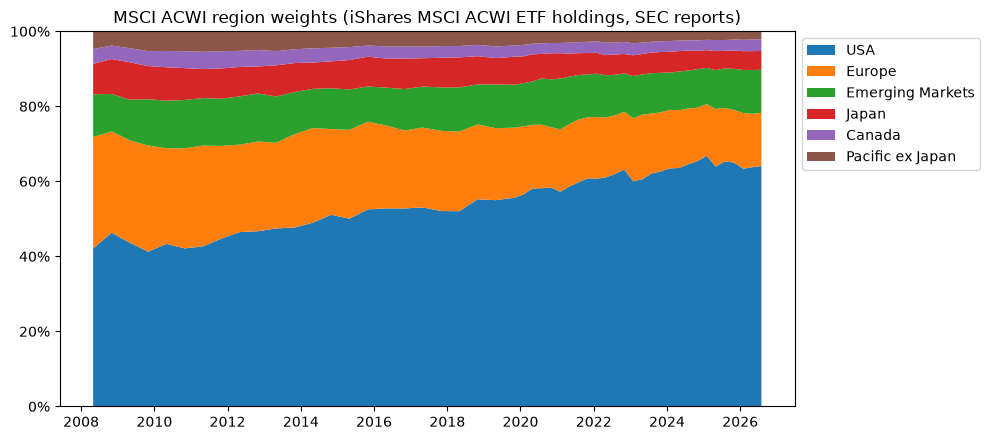

In [10]:
errors = {}
dates = acwi_weights.index
for previous, current in zip(dates[:-1], dates[1:]):
    rolled, _ = acwi_weights_on(current, acwi_weights.loc[:previous], region_prices(prices))
    actual = acwi_weights.loc[current, REGIONS].astype(float)
    errors[current] = (rolled - actual).abs().sum() / 2
errors = pd.Series(errors)
print(f"Roll-forward error to the next report: average {errors.mean():.2%}, largest {errors.max():.2%} ({errors.idxmax().date()})")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.stackplot(dates, acwi_weights[REGIONS].T.astype(float), labels=REGIONS)
ax.set_title("MSCI ACWI region weights (iShares MSCI ACWI ETF holdings, SEC reports)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig(OUTPUT / "fig_acwi_weights.png", dpi=200)
plt.show()

# 3. Backtest and performance measures
Three portfolios, each starting at 1:
- **Regional Momentum:** the strategy.
- **Passive replica:** the same six ETFs at ACWI weights, without tilt. It shows how well the six ETFs
  replicate the index, so the effect of the momentum signal can be measured on its own.
- **MSCI ACWI (ACWI ETF):** the benchmark.

In [11]:
result = run_all(prices, acwi_weights, rf, PARAMS)
navs = result["navs"]
returns = result["returns"]
table = result["table"]
table.to_csv(OUTPUT / "performance_table.csv")

print("Monthly returns from", returns.index[0].strftime("%b %Y"), "to", returns.index[-1].strftime("%b %Y"), f"({len(returns)} months)")

percent_columns = ["Average return p.a.", "Geometric return p.a.", "Volatility p.a.", "Alpha p.a.",
                   "Tracking error p.a.", "Max drawdown", "Turnover p.a.", "Trading costs p.a."]
pretty = table.copy()
for column in pretty.columns:
    number_format = "{:.2%}" if column in percent_columns else "{:.2f}"
    pretty[column] = table[column].map(lambda x: "" if pd.isna(x) else number_format.format(x))
pretty.T

Monthly returns from Jul 2008 to Oct 2026 (220 months)


,Regional Momentum,Passive replica,MSCI ACWI (ACWI ETF)
Average return p.a.,9.18%,9.63%,9.55%
Geometric return p.a.,8.11%,8.62%,8.50%
Volatility p.a.,16.33%,16.21%,16.43%
Sharpe ratio,0.48,0.51,0.50
Alpha p.a.,-0.30%,0.20%,-0.00%
Alpha t-stat,-1.03,0.89,
Beta,0.99,0.99,1.00
Tracking error p.a.,1.24%,0.97%,0.00%
Information ratio,-0.30,0.08,
Max drawdown,-46.22%,-44.91%,-45.80%


**Calculation assumptions**
- Monthly returns from month-end values (July 2008 to October 2026).
- Average return = arithmetic mean x 12; volatility = standard deviation x sqrt(12).
- Sharpe ratio = annualised average excess return over the T-bill rate / annualised volatility of the
  excess returns.
- Alpha and beta from the regression (r - rf) = alpha + beta x (r_ACWI - rf) + error on monthly excess
  returns. Alpha is multiplied by 12, beta is not annualised.
- Information ratio = annualised average active return (r - r_ACWI) / tracking error (annualised standard
  deviation of the active returns).
- Trading costs are deducted at each rebalancing; the initial purchase is not charged.

# 4. Figures and tables for the prospectus

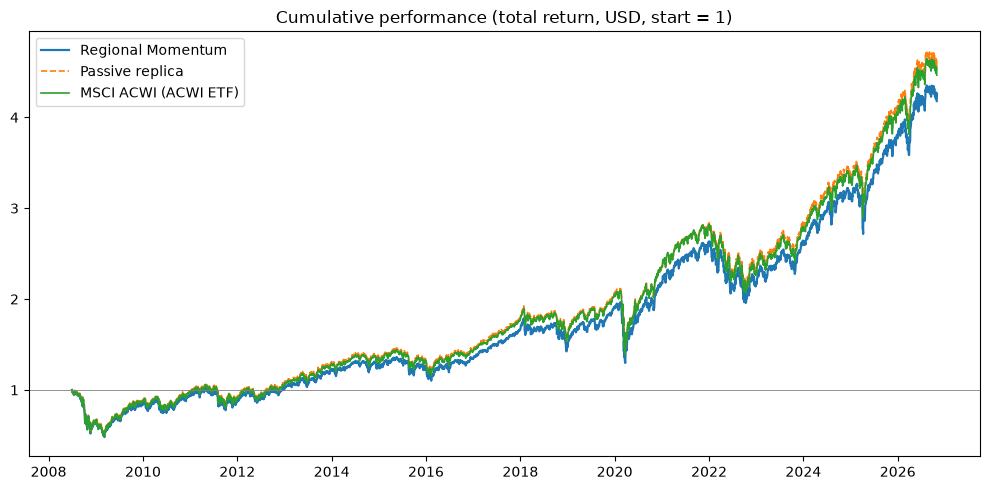

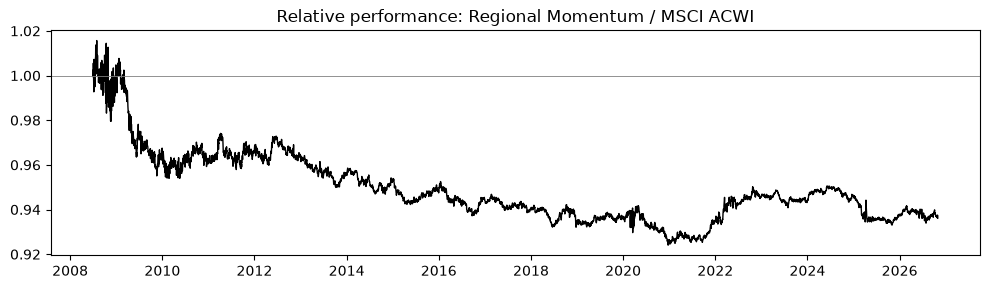

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(navs.index, navs["Regional Momentum"], label="Regional Momentum", lw=1.6)
ax.plot(navs.index, navs["Passive replica"], "--", label="Passive replica", lw=1.2)
ax.plot(navs.index, navs["MSCI ACWI (ACWI ETF)"], label="MSCI ACWI (ACWI ETF)", lw=1.2)
ax.axhline(1, color="grey", lw=0.6)
ax.set_title("Cumulative performance (total return, USD, start = 1)")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT / "fig_cumulative_performance.png", dpi=200)
plt.show()

relative = navs["Regional Momentum"] / navs["MSCI ACWI (ACWI ETF)"]
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(relative.index, relative, color="black", lw=1)
ax.axhline(1, color="grey", lw=0.6)
ax.set_title("Relative performance: Regional Momentum / MSCI ACWI")
fig.tight_layout()
fig.savefig(OUTPUT / "fig_relative_performance.png", dpi=200)
plt.show()

### Active weights over time (strategy minus passive replica)

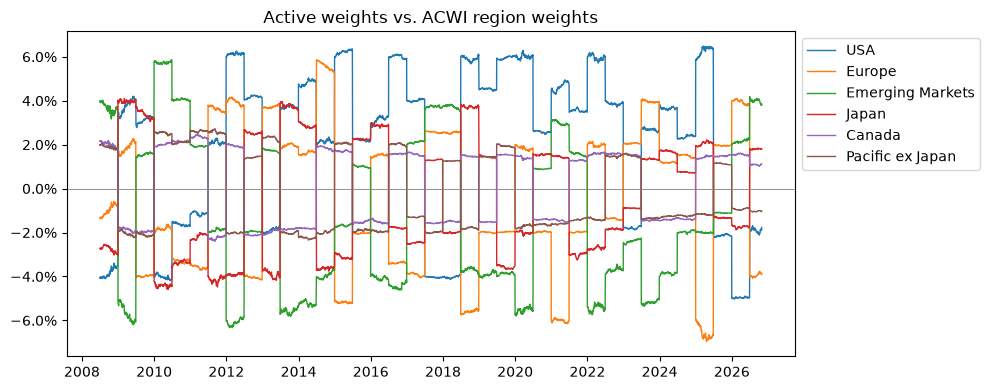

In [13]:
active_weights = result["strategy"].weights - result["passive"].weights

fig, ax = plt.subplots(figsize=(10, 4))
for region in REGIONS:
    ax.plot(active_weights.index, active_weights[region], label=region, lw=1)
ax.axhline(0, color="grey", lw=0.6)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Active weights vs. ACWI region weights")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig(OUTPUT / "fig_active_weights.png", dpi=200)
plt.show()

### Example of the allocation rule: the latest rebalancing date

In [14]:
trades = result["strategy"].trades
trades.to_csv(OUTPUT / "rebalancing_log.csv")
last = trades.iloc[-1]

example = pd.DataFrame(index=REGIONS)
example["ACWI weight"] = [last[f"base {region}"] for region in REGIONS]
example["Momentum"] = [last[f"signal {region}"] for region in REGIONS]
example["Rank"] = example["Momentum"].rank(ascending=False).astype(int)
example["Target weight"] = [last[f"target {region}"] for region in REGIONS]
example["Active weight"] = example["Target weight"] - example["ACWI weight"]
example = example.sort_values("Rank")
example.to_csv(OUTPUT / "example_rebalancing.csv")

print("Rebalancing on", trades.index[-1].date(), "- ACWI weights from the report as of", last["anchor"].date(),
      f"- turnover {last['turnover']:.1%}")
example.round(4)

Rebalancing on 2026-06-30 - ACWI weights from the report as of 2026-04-30 - turnover 17.0%


,ACWI weight,Momentum,Rank,Target weight,Active weight
Emerging Markets,0.1206,0.4459,1,0.1624,0.0418
Japan,0.0508,0.2977,2,0.0685,0.0177
Canada,0.0299,0.2647,3,0.0403,0.0104
USA,0.6376,0.2221,4,0.6176,-0.0200
Europe,0.1412,0.1851,5,0.1012,-0.0400
Pacific ex Japan,0.0199,0.1182,6,0.0099,-0.0099


### Turnover and trading costs per rebalancing date

In [15]:
trades[["anchor", "turnover", "cost"]].round(5)

/var/folders/r3/hfblp_7j5jlbmk6__3fmcclc0000gn/T/ipykernel_14599/2532139208.py:1: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  trades[["anchor", "turnover", "cost"]].round(5)


,anchor,turnover,cost
date,,,
2008-06-30,2008-04-30,0.00000,0.00000
2008-12-31,2008-10-31,0.31746,0.00048
2009-06-30,2009-04-30,0.14158,0.00021
2009-12-31,2009-10-31,0.30326,0.00045
2010-06-30,2010-04-30,0.07193,0.00011
2010-12-31,2010-10-31,0.05822,0.00009
2011-06-30,2011-04-30,0.20514,0.00031
2011-12-30,2011-10-31,0.16127,0.00024
2012-06-29,2011-10-31,0.27757,0.00042


### Calendar-year returns

In [16]:
year_end_values = navs.resample("YE").last()
annual = year_end_values.pct_change()
annual.iloc[0] = year_end_values.iloc[0] / navs.iloc[0] - 1  # 2008 starts on 30 June
annual.index = annual.index.year
annual["Active (vs. ACWI)"] = annual["Regional Momentum"] - annual["MSCI ACWI (ACWI ETF)"]
annual.to_csv(OUTPUT / "annual_returns.csv")

years_ahead = (annual["Active (vs. ACWI)"] > 0).sum()
print(f"The strategy beat the ACWI in {years_ahead} of {len(annual)} calendar years")
annual.round(4)

The strategy beat the ACWI in 5 of 19 calendar years


,Regional Momentum,Passive replica,MSCI ACWI (ACWI ETF),Active (vs. ACWI)
Date,,,,
2008,-0.3444,-0.3308,-0.3440,-0.0004
2009,0.2740,0.3122,0.3236,-0.0496
2010,0.1262,0.1231,0.1278,-0.0016
2011,-0.0735,-0.0715,-0.0782,0.0047
2012,0.1649,0.1714,0.1675,-0.0026
2013,0.2148,0.2235,0.2238,-0.0089
2014,0.0353,0.0380,0.0383,-0.0031
2015,-0.0283,-0.0243,-0.0221,-0.0063
2016,0.0801,0.0848,0.0840,-0.0039


# 5. Sensitivity analysis
Each row changes one assumption of the base case and keeps everything else as it is.

In [17]:
grid = {
    "rebalance": ["Q", "S", "A"],
    "lookback_months": [6, 12],
    "tilt_pp": [0.0, 3.0, 6.0, 10.0],
    "cost_bps": [0.0, 15.0, 50.0],
}
sens = sensitivity(prices, acwi_weights, rf, PARAMS, grid)
sens.to_csv(OUTPUT / "sensitivity.csv")
sens.round(4)

Average return p.a.  Volatility p.a.  Sharpe ratio  \
parameter       value                                                       
rebalance       Q                   0.0933           0.1619        0.4914   
                S                   0.0918           0.1633        0.4776   
                A                   0.0925           0.1634        0.4817   
lookback_months 6                   0.0948           0.1619        0.5004   
                12                  0.0918           0.1633        0.4776   
tilt_pp         0.0                 0.0963           0.1621        0.5089   
                3.0                 0.0933           0.1629        0.4881   
                6                   0.0918           0.1633        0.4776   
                10.0                0.0913           0.1636        0.4741   
cost_bps        0.0                 0.0923           0.1633        0.4806   
                15.0                0.0918           0.1633        0.4776   
                50.0                0.0906           0.1633        0.4706   

                       Alpha p.a.    Beta  Information ratio  Turnover p.a.  
parameter       value                                                        
rebalance       Q         -0.0008  0.9827            -0.1796         0.4320  
                S         -0.0030  0.9912            -0.3002         0.3239  
                A         -0.0023  0.9912            -0.2294         0.2318  
lookback_months 6          0.0007  0.9825            -0.0591         0.4001  
                12        -0.0030  0.9912            -0.3002         0.3239  
tilt_pp         0.0        0.0020  0.9852             0.0800         0.0242  
                3.0       -0.0013  0.9891            -0.2030         0.2076  
                6         -0.0030  0.9912            -0.3002         0.3239  
                10.0      -0.0035  0.9922            -0.3132         0.3941  
cost_bps        0.0       -0.0025  0.9912            -0.2611         0.3239  
                15.0      -0.0030  0.9912            -0.3002         0.3239  
                50.0      -0.0041  0.9911            -0.3898         0.3239

# 6. Check against the app
The Streamlit app imports the same functions from `regional_momentum/core.py`. With its default settings
it must show the numbers below.

In [18]:
main_numbers = table[["Average return p.a.", "Volatility p.a.", "Sharpe ratio", "Alpha p.a.", "Beta", "Information ratio"]]
(OUTPUT / "default_metrics.json").write_text(json.dumps(main_numbers.round(6).to_dict(orient="index"), indent=2))
main_numbers.round(4)

,Average return p.a.,Volatility p.a.,Sharpe ratio,Alpha p.a.,Beta,Information ratio
Regional Momentum,0.0918,0.1633,0.4776,-0.003,0.9912,-0.3002
Passive replica,0.0963,0.1621,0.5089,0.002,0.9852,0.0800
MSCI ACWI (ACWI ETF),0.0955,0.1643,0.4974,-0.000,1.0000,NaN
